# The degeneracy of $\lambda$ in `truncFLR`

Running `truncFLR.HH.lambda_select` as Hall & Hooker (2016) write it, i.e. method B, the selected $\lambda$ is the smallest candidate on the grid, whatever the data. The penalty is then doing nothing, and section 3.2 has given us an unpenalised endpoint scan.

This notebook works out why and fixes it. In short, step 6 pairs $S_Y$ with a bare $\lambda$ while equation (3.4) writes the penalty as $n \lambda \theta^2$, so the two displays disagree about $\lambda$ by a factor of $n$. Reading $S_Y$ as a sum makes $\lambda$ inert in the variance $V(\lambda)$, that variance collapses, the step-7 density ends up
narrower than the $\theta$ grid it is integrated on, and $P_b(\lambda)$ stops being an average of $S_b$ at all.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from truncFLR import HH, HH_dgp
from truncFLR import _common as C

plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

u, v = 0.8, 1.0
lambdas = np.linspace(0.0, 1.0, 250)[1:]
data = HH_dgp.sim_dataset(n=200, n_grid=301, u=u, v=v, snr=26.25, rng=5)
grid, Y = data["grid"], data["Y"]
X = data["X"][:, ::-1]                 # mirrored, so the true endpoint is theta = 0.2
a_pilot, b_pilot, fpc = HH.pilot_fpca(X, Y, grid)
print(f"n = {len(Y)}, grid spacing h = {grid[1] - grid[0]:.5f}")
print(f"BIC-selected components m = {fpc['m']}, true theta = {1 - u:.1f}")

n = 200, grid spacing h = 0.00333
BIC-selected components m = 8, true theta = 0.2


We reproduce the two readings of step 6 side by side. Both take
$\theta_\lambda$ from the same penalised objective, and both integrate $S_b$ against the same
normal density; they differ only in whether the $S_Y$ appearing in

$$V(\lambda) = \frac{\hat\sigma^2}{n} \frac{S_Y''(\theta_\lambda)}
{\{S_Y''(\theta_\lambda) + \lambda\}^2}$$

is the sum over $i$ that step 5 displays, or that sum divided by $n$. The `sum` branch is the
literal reading, and the `mean` branch is the one `truncFLR` uses.

In [3]:
def replay(diag, lambdas, n, reading, resolve=True):
    """Re-run step 6-7 from stored S_Y and S_b under either reading of S_Y."""
    S_Y, S_b, tg, sigma2 = diag["S_Y"], diag["S_b"], diag["theta_grid"], diag["sigma2"]
    h = tg[1] - tg[0]
    P_b = np.full(len(lambdas), np.nan)
    theta_lams, Vs = np.empty(len(lambdas)), np.full(len(lambdas), np.nan)

    for jx, lam in enumerate(lambdas):
        obj = S_Y + n * lam * tg ** 2
        idx = next((k for k in range(1, len(obj) - 1)
                    if obj[k] <= obj[k - 1] and obj[k] <= obj[k + 1]), int(np.argmin(obj)))
        theta_lams[jx] = tg[idx]

        j = min(max(idx, 1), len(tg) - 2)
        S_Y2 = (S_Y[j + 1] - 2 * S_Y[j] + S_Y[j - 1]) / h ** 2
        if reading == "mean":
            S_Y2 = S_Y2 / n
        if S_Y2 <= 0:
            continue
        V = (sigma2 / n) * S_Y2 / (S_Y2 + lam) ** 2
        Vs[jx] = V
        if resolve:
            P_b[jx] = C.weighted_S_b(S_b, tg, tg[idx], V, C.normal_weight)
        else:
            P_b[jx] = np.trapezoid(S_b * C.normal_weight(tg, tg[idx], V), tg)

    return {"lam_hat": lambdas[int(np.nanargmin(P_b))], "P_b": P_b,
            "theta_lams": theta_lams, "Vs": Vs}


_, diag = HH.lambda_select(X, Y, grid, a_pilot, b_pilot, fpc, None, lambdas)
literal = replay(diag, lambdas, len(Y), "sum", resolve=False)
print(f"literal reading: lambda_hat = {literal['lam_hat']:.5f}, "
      f"smallest candidate = {lambdas[0]:.5f}")

literal reading: lambda_hat = 0.00402, smallest candidate = 0.00402


So $\hat\lambda$ sits on the floor of the grid. We check that this is not one unlucky seed.

In [4]:
floor_hits = 0
for seed in range(10):
    d = HH_dgp.sim_dataset(n=200, n_grid=301, u=u, v=v, snr=26.25, rng=seed)
    Xs = d["X"][:, ::-1]
    a_s, b_s, fpc_s = HH.pilot_fpca(Xs, d["Y"], grid)
    _, dg = HH.lambda_select(Xs, d["Y"], grid, a_s, b_s, fpc_s, None, lambdas)
    floor_hits += replay(dg, lambdas, len(d["Y"]), "sum", resolve=False)["lam_hat"] == lambdas[0]
print(f"lambda_hat on the grid floor: {floor_hits}/10 seeds")

lambda_hat on the grid floor: 10/10 seeds


## Where it comes from

$P_b(\lambda) = \int S_b(\theta)\, N(\theta; \theta_\lambda, V(\lambda))\, d\theta$ depends on
$\lambda$ only through $\theta_\lambda$ and $V$. We look at each in turn, starting with the
two error curves themselves.

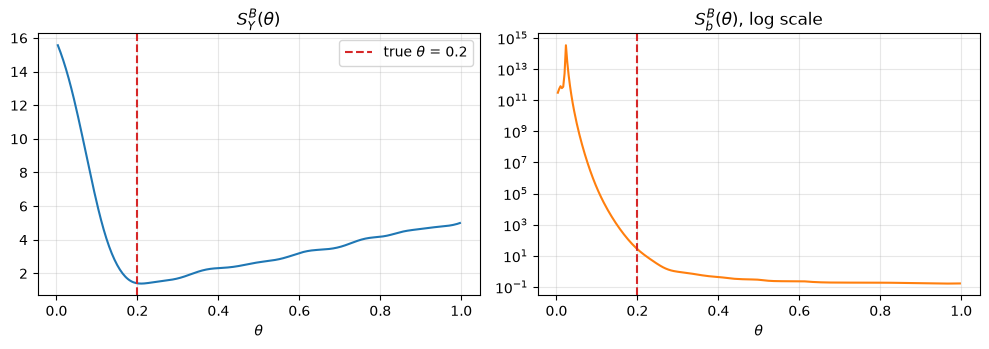

S_Y is minimised at theta = 0.210
S_b is minimised at theta = 0.963, at the right-hand end
S_b(0.1) = 2.23e+05,  S_b(0.9) = 0.17


In [5]:
tg, S_Y, S_b = diag["theta_grid"], diag["S_Y"], diag["S_b"]

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(tg, S_Y, color="C0")
ax[0].axvline(1 - u, color="C3", ls="--", label=fr"true $\theta$ = {1 - u:.1f}")
ax[0].set_xlabel(r"$\theta$"); ax[0].set_title(r"$S_Y^B(\theta)$")
ax[0].legend()

ax[1].semilogy(tg, S_b, color="C1")
ax[1].axvline(1 - u, color="C3", ls="--")
ax[1].set_xlabel(r"$\theta$"); ax[1].set_title(r"$S_b^B(\theta)$, log scale")

plt.tight_layout(); plt.show()

print(f"S_Y is minimised at theta = {tg[np.argmin(S_Y)]:.3f}")
print(f"S_b is minimised at theta = {tg[np.argmin(S_b)]:.3f}, at the right-hand end")
print(f"S_b(0.1) = {S_b[np.argmin(abs(tg - 0.1))]:.3g},  "
      f"S_b(0.9) = {S_b[np.argmin(abs(tg - 0.9))]:.3g}")

We can see that $S_Y^B$ is well behaved, with an interior minimum close to the truth. $S_b^B$
is not: it spans fifteen orders of magnitude and decreases over essentially the whole grid.
Its variance term is

$$\hat\sigma^2 \sum_{j=1}^m (\tau_j^\theta)^{-1} \int_0^\theta (\hat\phi_j^1)^2,$$

and the truncated eigenvalues $\tau_j^\theta$ all vanish as $\theta \to 0$, faster the larger
$j$ is. At the BIC-selected $m$ that divergence swamps the reconstruction bias everywhere, so
$S_b$ is monotone. Since a larger $\lambda$ pushes $\theta_\lambda$ left, and left is where
$S_b$ is worse, $P_b$ can only increase with $\lambda$.

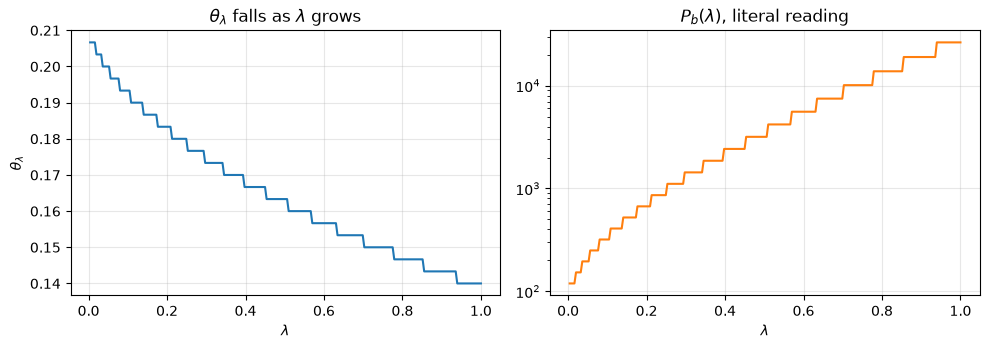

P_b is increasing in lambda everywhere: True


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(lambdas, literal["theta_lams"], color="C0")
ax[0].set_xlabel(r"$\lambda$"); ax[0].set_ylabel(r"$\theta_\lambda$")
ax[0].set_title(r"$\theta_\lambda$ falls as $\lambda$ grows")

ax[1].semilogy(lambdas, literal["P_b"], color="C1")
ax[1].set_xlabel(r"$\lambda$"); ax[1].set_title(r"$P_b(\lambda)$, literal reading")
plt.tight_layout(); plt.show()

increasing = np.all(np.diff(literal["P_b"][~np.isnan(literal["P_b"])]) > 0)
print(f"P_b is increasing in lambda everywhere: {increasing}")

## The variance collapses

That is only half of it. The other half is $V(\lambda)$, which sets the width of the step-7
density. $S_Y$ is a sum over $n$ observations, so $S_Y''$ is of order $n$; a $\lambda$ of order
one added to it changes nothing.

In [7]:
h = tg[1] - tg[0]
S_Y2 = np.gradient(np.gradient(S_Y, h), h)
idx0 = int(np.argmin(S_Y))
print(f"S_Y'' near its minimum      = {S_Y2[idx0]:.4g}   (order n = {len(Y)})")
print(f"lambda grid                 = [{lambdas[0]:.4g}, {lambdas[-1]:.4g}]")
ratio_lo = (S_Y2[idx0] + lambdas[0]) / S_Y2[idx0]
ratio_hi = (S_Y2[idx0] + lambdas[-1]) / S_Y2[idx0]
print(f"(S_Y'' + lambda) / S_Y''    in [{ratio_lo:.12f}, {ratio_hi:.6f}]")
print()
sd = np.sqrt(literal["Vs"])
print(f"sd of the step-7 density    = {np.nanmin(sd):.6f} to {np.nanmax(sd):.6f}")
print(f"theta grid spacing h        = {h:.6f}")
print(f"grid points per sd          = {np.nanmedian(sd) / h:.3f}")

S_Y'' near its minimum      = 301.8   (order n = 200)
lambda grid                 = [0.004016, 1]
(S_Y'' + lambda) / S_Y''    in [1.000013306124, 1.003313]

sd of the step-7 density    = 0.000117 to 0.000209
theta grid spacing h        = 0.003333
grid points per sd          = 0.039


The density is roughly twenty-five times narrower than the spacing of the grid it is
integrated on. A trapezium rule cannot see it: the integral collapses to the one grid point
nearest $\theta_\lambda$, weighted by $h / \sqrt{2\pi V}$, so

$$P_b(\lambda) \;\approx\; \frac{h}{\sqrt{2\pi V(\lambda)}}\, S_b(\theta_\lambda),$$

which is not an average of $S_b$ at all. We check that this is what the unresolved integral
is returning.

In [8]:
approx = h * np.interp(literal["theta_lams"], tg, S_b) / np.sqrt(2 * np.pi * literal["Vs"])
ok = ~np.isnan(literal["P_b"])
rel = np.abs(approx[ok] - literal["P_b"][ok]) / literal["P_b"][ok]
print("median relative gap between P_b and h S_b(theta_lambda) / sqrt(2 pi V): "
      f"{np.median(rel):.4f}")
print(f"range of S_b over the grid : [{S_b.min():.4g}, {S_b.max():.4g}]")
print(f"range of P_b               : [{np.nanmin(literal['P_b']):.4g}, "
      f"{np.nanmax(literal['P_b']):.4g}]")
print("P_b leaves the range of S_b entirely, so it is not a weighted average of it.")

median relative gap between P_b and h S_b(theta_lambda) / sqrt(2 pi V): 0.0000
range of S_b over the grid : [0.1636, 3.376e+14]
range of P_b               : [119.3, 2.633e+04]
P_b leaves the range of S_b entirely, so it is not a weighted average of it.


## The correction

Equation (3.4) writes the penalty as $n \lambda \theta^2$, with the $n$ inserted because
"both $S$ and $S_1$ are of order $n$". Step 6 then writes $S_Y + \lambda \theta^2$ and
$(S_Y'' + \lambda)^2$. One $\lambda$ can serve both only if the $S_Y$ in step 6 is the
per-observation error $S_Y / n$, and that is also the reading under which $V$ is of order
$\hat\sigma^2/n$ rather than $\hat\sigma^2/n^2$, i.e. the order a variance should be.

`truncFLR` takes that reading, and integrates step 7 on a grid refined to resolve the density
rather than on the $\theta$ grid. We apply the two changes one at a time.

In [9]:
READINGS = [("literal, unresolved", "sum", False),
            ("literal, resolved", "sum", True),
            ("mean, unresolved", "mean", False),
            ("mean, resolved", "mean", True)]

variants = {name: replay(diag, lambdas, len(Y), reading, resolve=res)
            for name, reading, res in READINGS}

# How often each reading escapes the floor, over independent datasets.
n_seeds = 20
cached = []
for seed in range(n_seeds):
    d = HH_dgp.sim_dataset(n=200, n_grid=301, u=u, v=v, snr=26.25, rng=seed)
    Xs = d["X"][:, ::-1]
    a_s, b_s, fpc_s = HH.pilot_fpca(Xs, d["Y"], grid)
    cached.append((HH.lambda_select(Xs, d["Y"], grid, a_s, b_s, fpc_s, None, lambdas)[1],
                   len(d["Y"])))

print(f"{'reading':22} {'lambda_hat':>11} {'sd(theta_lam)':>14} {'pts per sd':>11} "
      f"{'interior over ' + str(n_seeds) + ' seeds':>26}")
for name, reading, res in READINGS:
    r = variants[name]
    sd = np.nanmedian(np.sqrt(r["Vs"]))
    interior = sum(replay(dg, lambdas, nn, reading, resolve=res)["lam_hat"] > lambdas[0]
                   for dg, nn in cached)
    print(f"{name:22} {r['lam_hat']:11.5f} {sd:14.6f} {sd / h:11.2f} "
          f"{str(interior) + '/' + str(n_seeds):>26}")

reading                 lambda_hat  sd(theta_lam)  pts per sd     interior over 20 seeds
literal, unresolved        0.00402       0.000129        0.04                       0/20
literal, resolved          0.01606       0.000129        0.04                      13/20
mean, unresolved           0.01606       0.001650        0.49                      13/20
mean, resolved             0.01606       0.001650        0.49                      13/20


Either change alone lifts the degeneracy, and they do it for different reasons. Resolving the
quadrature makes $P_b$ a genuine average of $S_b$, no matter what $V$ turns out to be, which is what
the paper's display asks for. The mean reading widens the density by a factor of $\sqrt{n}$,
which leaves it still finer than the grid but no longer invisible to it.

The mean reading is the one that has to be right regardless, since it is the only reading under
which a single $\lambda$ serves both step-6 displays, and the only one under which $V$ is of
order $\hat\sigma^2/n$, the order a variance of an estimator should have. `truncFLR` applies
both. We plot $P_b$ under each.

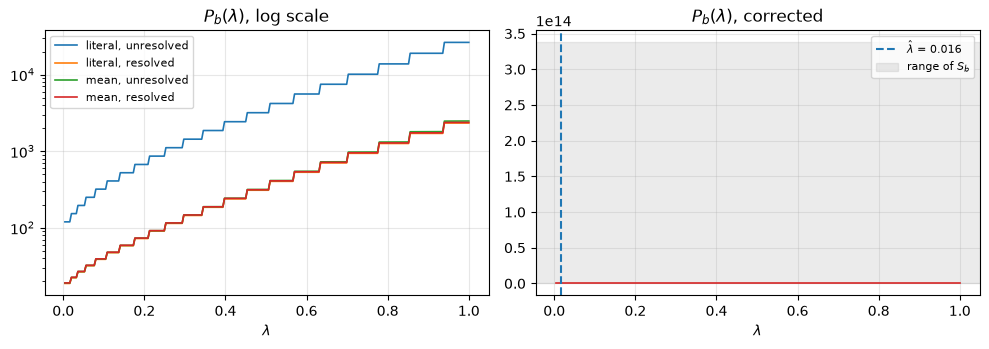

corrected P_b stays inside the range of S_b: True


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for name, r in variants.items():
    ax[0].semilogy(lambdas, r["P_b"], lw=1.2, label=name.strip())
ax[0].set_xlabel(r"$\lambda$"); ax[0].set_title(r"$P_b(\lambda)$, log scale")
ax[0].legend(fontsize=8)

corrected = variants["mean, resolved"]
ax[1].plot(lambdas, corrected["P_b"], color="C3", lw=1.2)
ax[1].axvline(corrected["lam_hat"], color="C0", ls="--",
              label=fr"$\hat\lambda$ = {corrected['lam_hat']:.3f}")
ax[1].axhspan(S_b.min(), S_b.max(), color="C7", alpha=0.15,
              label=r"range of $S_b$")
ax[1].set_xlabel(r"$\lambda$"); ax[1].set_title(r"$P_b(\lambda)$, corrected")
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

inside = np.all((corrected["P_b"][~np.isnan(corrected["P_b"])] >= S_b.min())
                & (corrected["P_b"][~np.isnan(corrected["P_b"])] <= S_b.max()))
print(f"corrected P_b stays inside the range of S_b: {inside}")

$P_b$ now lies inside the range of $S_b$, as an average of it must, and has an interior
minimum. We confirm that `HH.lambda_select` itself, which applies both corrections, agrees.

In [10]:
lam_hat, _ = HH.lambda_select(X, Y, grid, a_pilot, b_pilot, fpc, None, lambdas)
print(f"HH.lambda_select        : lambda_hat = {lam_hat:.5f}")
print(f"replay, mean + resolved : lambda_hat = {corrected['lam_hat']:.5f}")

HH.lambda_select        : lambda_hat = 0.01606
replay, mean + resolved : lambda_hat = 0.01606


## What it buys

The endpoint estimate is what we actually care about, so we run both methods over independent
datasets and compare the recovered $\hat u$ and the integrated squared error of $\hat b$
against the untruncated pilot.

In [11]:
n_rep = 25
rows = {}
pilot_ise = []
for label in ("B", "A"):
    errs, ises, lams = [], [], []
    for r in range(n_rep):
        d = HH_dgp.sim_dataset(n=200, n_grid=301, u=u, v=v, snr=26.25, rng=r)
        if label == "B":
            res = HH.fit_mirror(d["X"], d["Y"], d["grid"], lambdas)
            _, bp, _ = HH.pilot_fpca(d["X"], d["Y"], d["grid"])
            pilot_ise.append(np.trapezoid((bp - d["b"]) ** 2, d["grid"]))
        else:
            from truncFLR import HH_A
            res = HH_A.fit_mirror(d["X"], d["Y"], d["grid"], lambdas)
        errs.append(res["u_hat"] - d["u"])
        ises.append(np.trapezoid((res["b_hat"] - d["b"]) ** 2, d["grid"]))
        lams.append(res["lam_hat"])
    rows[label] = (np.array(errs), np.array(ises), np.array(lams))

print(f"{n_rep} replications, n=200, n_grid=301, snr=26.25\n")
print(f"{'method':>8} {'bias(u)':>9} {'sd(u)':>8} {'RMSE(u)':>9} {'mean ISE':>10} "
      f"{'interior lambda':>16}")
for label, (e, i, lam) in rows.items():
    print(f"{label:>8} {e.mean():+9.4f} {e.std(ddof=1):8.4f} {np.sqrt((e ** 2).mean()):9.4f} "
          f"{i.mean():10.4f} {int((lam > lambdas[0]).sum()):>11}/{n_rep}")
print(f"\nuntruncated pilot mean ISE = {np.mean(pilot_ise):.4f}")

25 replications, n=200, n_grid=301, snr=26.25

  method   bias(u)    sd(u)   RMSE(u)   mean ISE  interior lambda
       B   -0.0287   0.0075    0.0296     0.0120          16/25
       A   -0.0024   0.0092    0.0093     0.0091           3/25

untruncated pilot mean ISE = 0.0219


Both methods now beat the untruncated pilot, method B picks an interior $\lambda$ on most
seeds, and method A is very nearly unbiased. Method A still lands on the grid floor often, and
that is not a failure of the criterion: its $S_Y^A$ carries the constant $\hat\sigma^2(m+1)$
in place of method B's $\theta$-dependent variance term, so its own minimum already sits near
the truth and the penalty has little left to correct.

## Capping the components

`m_tuning` caps $m$ inside the §3.2 criterion only, leaving the pilot and the final fit alone.
It attacks the same $\sum_j (\tau_j^\theta)^{-1}$ term directly, by dropping the components
whose truncated eigenvalues are smallest, so it is worth seeing what it does now that the
scaling is right.

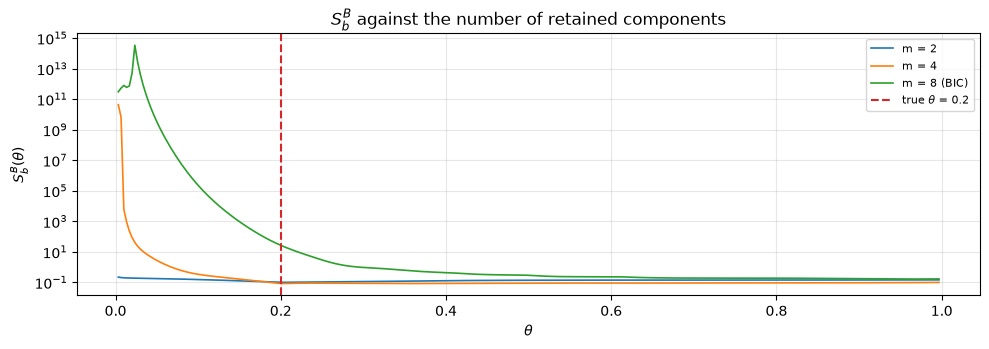

In [12]:
fig, ax = plt.subplots(figsize=(10, 3.6))
for m_cap in (2, 4, fpc["m"]):
    phi_cap = fpc["m"] if m_cap == fpc["m"] else m_cap
    _, dg = HH.lambda_select(X, Y, grid, a_pilot, b_pilot, fpc, None, lambdas,
                             m_tuning=None if m_cap == fpc["m"] else m_cap)
    lab = f"m = {phi_cap}" + (" (BIC)" if m_cap == fpc["m"] else "")
    ax.semilogy(dg["theta_grid"], dg["S_b"], lw=1.2, label=lab)
ax.axvline(1 - u, color="C3", ls="--", label=fr"true $\theta$ = {1 - u:.1f}")
ax.set_xlabel(r"$\theta$"); ax.set_ylabel(r"$S_b^B(\theta)$")
ax.set_title(r"$S_b^B$ against the number of retained components")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [13]:
errs = {}
for m_cap in (None, 2):
    e, i = [], []
    for r in range(n_rep):
        d = HH_dgp.sim_dataset(n=200, n_grid=301, u=u, v=v, snr=26.25, rng=r)
        res = HH.fit_mirror(d["X"], d["Y"], d["grid"], lambdas, m_tuning=m_cap)
        e.append(res["u_hat"] - d["u"])
        i.append(np.trapezoid((res["b_hat"] - d["b"]) ** 2, d["grid"]))
    errs[m_cap] = (np.array(e), np.array(i))

print(f"{'m_tuning':>9} {'bias(u)':>9} {'sd(u)':>8} {'RMSE(u)':>9} {'mean ISE':>10} "
      f"{'sd ISE':>9}")
for m_cap, (e, i) in errs.items():
    print(f"{str(m_cap):>9} {e.mean():+9.4f} {e.std(ddof=1):8.4f} "
          f"{np.sqrt((e ** 2).mean()):9.4f} {i.mean():10.4f} {i.std(ddof=1):9.4f}")

 m_tuning   bias(u)    sd(u)   RMSE(u)   mean ISE    sd ISE
     None   -0.0287   0.0075    0.0296     0.0120    0.0048
        2   +0.0260   0.0083    0.0273     0.9170    1.7780


Capping $m$ does flatten $S_b$, and it does buy a slightly better endpoint RMSE, but it
overshoots: $\hat u$ is biased upwards, i.e. the window is cut too short, and every point of
the informative region lost that way costs the refit far more than the endpoint error suggests.
The integrated squared error of $\hat b$ is worse by two orders of magnitude. So `m_tuning` is
a diagnostic for isolating the $\sum_j (\tau_j^\theta)^{-1}$ term, not a setting to run with;
with steps 6 and 7 on the right scale, the paper's procedure needs no cap.

## Summary

The degeneracy was never in $S_Y^B$, which behaves well, nor in the estimator itself. Two
things combine to produce it, and both are matters of reading rather than of method.

Step 6 pairs $S_Y$ with a bare $\lambda$ where equation (3.4) has already absorbed a factor $n$
into it. Taken as the sum step 5 displays, $\lambda$ is invisible to $V(\lambda)$ and $V$ comes
out at order $\hat\sigma^2/n^2$, which is too small by a factor of $n$ for a variance. The
resulting density is finer than the $\theta$ grid, and integrating it there by the trapezium
rule returns $S_b(\theta_\lambda)$ scaled by $h/\sqrt{2\pi V}$ rather than an average of $S_b$.
Since $S_b$ is monotone at the BIC-selected $m$, $P_b$ inherits that monotonicity and
$\hat\lambda$ goes to the floor.

Reading $S_Y$ per observation and integrating step 7 on a grid that resolves the density fixes
both, and either correction on its own is enough to recover an interior $\hat\lambda$ on most
seeds. With them, the endpoint estimate beats the untruncated pilot and method A is very nearly
unbiased.